In [2]:
%pip install --user torch torchvision torchaudio --index-url https://download.pytorch.org/whl/cu121

Looking in indexes: https://download.pytorch.org/whl/cu121
Note: you may need to restart the kernel to use updated packages.


In [1]:
import torch

print("Is CUDA available?:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU Name:", torch.cuda.get_device_name(0))

Is CUDA available?: True
GPU Name: NVIDIA GeForce RTX 4060 Laptop GPU


In [2]:
import torch
print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("CUDA version (torch):", torch.version.cuda)
print("cuDNN version:", torch.backends.cudnn.version() if torch.backends.cudnn.is_available() else "Not available")

PyTorch version: 2.5.1+cu121
CUDA available: True
CUDA version (torch): 12.1
cuDNN version: 90100


In [3]:
import subprocess
import sys

# Check nvidia-smi
try:
    result = subprocess.run(['nvidia-smi'], capture_output=True, text=True)
    print(result.stdout[:500])  # First 500 chars
except FileNotFoundError:
    print("nvidia-smi not found. NVIDIA drivers may not be installed.")

Fri Jun  5 22:24:12 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 596.36                 Driver Version: 596.36         CUDA Version: 13.2     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                  Driver-Model | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|       


In [4]:
# Uninstall CPU version first
import sys
import subprocess

# Uninstall from all locations
!pip uninstall torch torchvision torchaudio -y
!python -m pip uninstall torch torchvision torchaudio -y

Found existing installation: torch 2.5.1+cu121
Uninstalling torch-2.5.1+cu121:
  Successfully uninstalled torch-2.5.1+cu121
Found existing installation: torchvision 0.20.1+cu121
Uninstalling torchvision-0.20.1+cu121:
  Successfully uninstalled torchvision-0.20.1+cu121
Found existing installation: torchaudio 2.5.1+cu121
Uninstalling torchaudio-2.5.1+cu121:
  Successfully uninstalled torchaudio-2.5.1+cu121
Found existing installation: torch 2.12.0
Uninstalling torch-2.12.0:
  Successfully uninstalled torch-2.12.0
Found existing installation: torchvision 0.27.0
Uninstalling torchvision-0.27.0:
  Successfully uninstalled torchvision-0.27.0
Found existing installation: torchaudio 2.11.0
Uninstalling torchaudio-2.11.0:
  Successfully uninstalled torchaudio-2.11.0


You can safely remove it manually.


In [5]:
# Install CUDA 12.1 version (compatible with your setup)
!pip install torch torchvision torchaudio --index-url https://download.pytorch.org/whl/cu121

Looking in indexes: https://download.pytorch.org/whl/cu121
  Using cached torch-2.5.1%2Bcu121-cp312-cp312-win_amd64.whl (2449.3 MB)
  Using cached torchvision-0.20.1%2Bcu121-cp312-cp312-win_amd64.whl (6.1 MB)
  Using cached torchaudio-2.5.1%2Bcu121-cp312-cp312-win_amd64.whl (4.1 MB)

   ---------------------------------------- 0/3 [torch]
   ---------------------------------------- 0/3 [torch]
   ---------------------------------------- 0/3 [torch]
   ---------------------------------------- 0/3 [torch]
   ---------------------------------------- 0/3 [torch]
   ---------------------------------------- 0/3 [torch]
   ---------------------------------------- 0/3 [torch]
   ---------------------------------------- 0/3 [torch]
   ---------------------------------------- 0/3 [torch]
   ---------------------------------------- 0/3 [torch]
   ---------------------------------------- 0/3 [torch]
   ---------------------------------------- 0/3 [torch]
   ----------------------------------------

In [4]:
# Test basic GPU operations
import torch

# Create tensors on GPU
x = torch.randn(1000, 1000).cuda()
y = torch.randn(1000, 1000).cuda()

# Perform matrix multiplication (uses GPU)
z = torch.mm(x, y)

print(f"Tensor device: {z.device}")
print(f"Matrix multiplication shape: {z.shape}")
print(f"Operation successful on GPU!")

Tensor device: cuda:0
Matrix multiplication shape: torch.Size([1000, 1000])
Operation successful on GPU!


In [5]:
# Compare CPU vs GPU speed
import time

# CPU
cpu_tensor = torch.randn(3000, 3000)
start = time.time()
cpu_result = torch.mm(cpu_tensor, cpu_tensor)
cpu_time = time.time() - start

# GPU
gpu_tensor = torch.randn(3000, 3000).cuda()
start = time.time()
gpu_result = torch.mm(gpu_tensor, gpu_tensor)
torch.cuda.synchronize()  # Wait for GPU to finish
gpu_time = time.time() - start

print(f"CPU time: {cpu_time:.4f} seconds")
print(f"GPU time: {gpu_time:.4f} seconds")
print(f"GPU is {cpu_time/gpu_time:.1f}x faster!")

CPU time: 6.7368 seconds
GPU time: 0.0752 seconds
GPU is 89.6x faster!


In [6]:
def linear_q_with_scale_and_zero_point(
    tensor, scale, zero_point, dtype=torch.int8):
    
    scaled_and_shifted_tesnor = tensor / scale + zero_point
    
    rounded_tensor = torch.round(scaled_and_shifted_tesnor)
    
    q_min = torch.iinfo(dtype).min
    q_max = torch.iinfo(dtype).max
    
    q_tensor = rounded_tensor.clamp(q_min,q_max).to(dtype)
    
    print('h')
    
    return q_tensor


In [7]:
### a dummy tensor to test the implementation
test_tensor=torch.tensor(
    [[191.6, -13.5, 728.6],
     [92.14, 295.5,  -184],
     [0,     684.6, 245.5]]
)

In [8]:
### these are random values for "scale" and "zero_point"
### to test the implementation
scale = 3.5
zero_point = -70

In [9]:
quantized_tensor = linear_q_with_scale_and_zero_point(
    test_tensor, scale, zero_point)

h


In [10]:
quantized_tensor

tensor([[ -15,  -74,  127],
        [ -44,   14, -123],
        [ -70,  126,    0]], dtype=torch.int8)

In [11]:
dequantized_tensor = scale * (quantized_tensor.float() - zero_point)

In [12]:
# this was the original tensor
# [[191.6, -13.5, 728.6],
#  [92.14, 295.5,  -184],
#  [0,     684.6, 245.5]]

In [13]:
dequantized_tensor

tensor([[ 192.5000,  -14.0000,  689.5000],
        [  91.0000,  294.0000, -185.5000],
        [   0.0000,  686.0000,  245.0000]])

In [14]:
def linear_dequantization(quantized_tensor, scale, zero_point):
    return scale * (quantized_tensor.float() - zero_point)

In [15]:
dequantized_tensor = linear_dequantization(
    quantized_tensor, scale, zero_point)

In [16]:
dequantized_tensor

tensor([[ 192.5000,  -14.0000,  689.5000],
        [  91.0000,  294.0000, -185.5000],
        [   0.0000,  686.0000,  245.0000]])

In [19]:
from helper import plot_quantization_errors

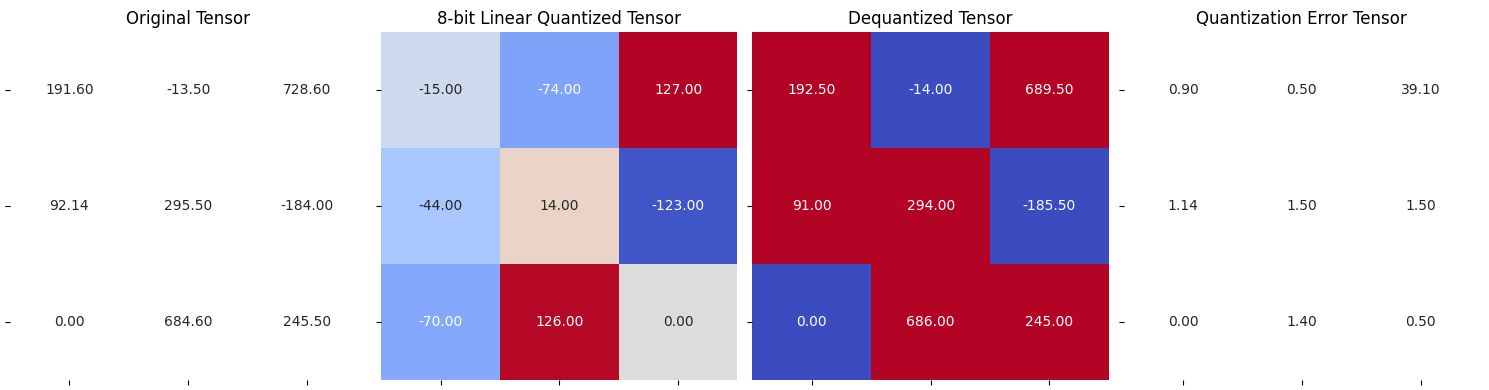

In [20]:
plot_quantization_errors(test_tensor, quantized_tensor,
                         dequantized_tensor)

In [21]:
dequantized_tensor - test_tensor

tensor([[  0.9000,  -0.5000, -39.1000],
        [ -1.1400,  -1.5000,  -1.5000],
        [  0.0000,   1.4000,  -0.5000]])

In [22]:
(dequantized_tensor - test_tensor).square()

tensor([[8.0999e-01, 2.5000e-01, 1.5288e+03],
        [1.2996e+00, 2.2500e+00, 2.2500e+00],
        [0.0000e+00, 1.9601e+00, 2.5000e-01]])

In [23]:
(dequantized_tensor - test_tensor).square().mean()

tensor(170.8753)